# Phase 1 — Découverte du Dataset

**Objectifs:**
- [x] Téléchargement Dataset
- [x] Étude du Schema
- [x] Comprendre chaque Column
- [x] Analyse Nulls et Duplicates
- [x] Data Dictionary

**Livrable:** Dataset analysé

**Dataset:** NYC TLC Yellow Taxi Trips — janvier 2024 (Parquet) + Taxi Zone Lookup (CSV)

## 0. Setup

In [1]:
from lakehouse_config import *
spark = get_spark()
setup_schemas(spark)

from pyspark.sql import functions as F
from pyspark.sql.types import *

## 1. Téléchargement Dataset

In [2]:
trips_path = upload_to_volume(TRIPS_URL.format(month="2024-01"), "yellow_tripdata_2024-01.parquet")
zones_path = upload_to_volume(ZONES_FILE, ZONES_FILE)
print(trips_path)
print(zones_path)

Deja kayn: /Volumes/workspace/raw/landing/yellow_tripdata_2024-01.parquet


Deja kayn: /Volumes/workspace/raw/landing/taxi_zone_lookup.csv
/Volumes/workspace/raw/landing/yellow_tripdata_2024-01.parquet
/Volumes/workspace/raw/landing/taxi_zone_lookup.csv


In [3]:
trips = spark.read.parquet(trips_path)
zones = spark.read.csv(zones_path, header=True, inferSchema=True)

print("Trips:", trips.count())
print("Zones:", zones.count())

Trips: 2964624


Zones: 265


## 2. Étude du Schema

In [4]:
trips.printSchema()

root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)



In [5]:
zones.printSchema()

root
 |-- LocationID: integer (nullable = true)
 |-- Borough: string (nullable = true)
 |-- Zone: string (nullable = true)
 |-- service_zone: string (nullable = true)



### Observations — Schema

- **Trips** (19 colonnes): identifiants (vendor, zones), timestamps pickup/dropoff, informations du trajet et 9 colonnes de montants.
- **Zones** (4 colonnes): référentiel des 265 zones TLC (`LocationID` → `Borough`, `Zone`, `service_zone`).
- **Relations:** `trips.PULocationID` et `trips.DOLocationID` → `zones.LocationID` (N:1).
- **Nullability:** toutes les colonnes sont `nullable = true` → aucune garantie de complétude côté source.

**Points d'attention sur les types (à corriger en Silver):**
| Colonne | Type actuel | Problème | Type cible |
|---|---|---|---|
| `passenger_count`, `RatecodeID`, `payment_type` | `long` | Codes / petits entiers, `long` surdimensionné | `int` |
| Montants (`fare_amount` … `Airport_fee`) | `double` | Imprécision flottante sur des montants monétaires | `decimal(10,2)` |
| `tpep_*_datetime` | `timestamp_ntz` | Pas de fuseau horaire (heure locale NYC implicite) | `timestamp` |
| `Airport_fee`, `VendorID`, `PULocationID`… | — | Nommage incohérent (CamelCase / majuscules) | `snake_case` |

## 3. Comprendre chaque Column

### 3.1 Modèle des données

In [6]:

from IPython.display import display, HTML

display(HTML("""
<style>
.uml-container {
    font-family: Arial, sans-serif;
    padding: 20px;
    background: #f1f5f9;
    border-radius: 12px;
    color: #1e293b;
}
.uml-title {
    text-align: center;
    font-size: 22px;
    font-weight: bold;
    margin-bottom: 25px;
}
.uml-layout {
    display: grid;
    grid-template-columns: 2fr 1fr 1fr;
    gap: 15px;
    align-items: center;
}
.uml-class {
    background: white;
    border: 2px solid #334155;
    border-radius: 7px;
    overflow: hidden;
    box-shadow: 0 3px 8px #00000012;
}
.uml-header {
    background: #2563eb;
    color: white;
    text-align: center;
    padding: 12px;
    font-size: 18px;
    font-weight: bold;
}
.uml-header.zones {
    background: #15803d;
}
.uml-body {
    padding: 12px 15px;
}
.uml-field {
    display: flex;
    justify-content: space-between;
    gap: 8px;
    padding: 5px 0;
    border-bottom: 1px solid #e2e8f0;
    font-size: 12px;
}
.uml-field:last-child {
    border-bottom: none;
}
.uml-type {
    color: #64748b;
    white-space: nowrap;
}
.uml-relations {
    text-align: center;
    font-size: 12px;
    font-weight: bold;
    color: #334155;
    line-height: 2;
}
.uml-arrow {
    color: #2563eb;
    font-size: 24px;
    font-weight: bold;
}
.uml-note {
    text-align: center;
    margin-top: 20px;
    background: white;
    border-radius: 7px;
    padding: 12px;
    font-size: 13px;
}
@media(max-width: 750px) {
    .uml-layout {
        grid-template-columns: 1fr;
    }
}
</style>

<div class="uml-container">

<div class="uml-title">
    NYC TAXI DATASET — UML CLASS DIAGRAM
</div>

<div class="uml-layout">

<!-- TRIPS CLASS -->
<div class="uml-class">
    <div class="uml-header">trips</div>
    <div class="uml-body">

        <div class="uml-field"><b>VendorID</b><span class="uml-type">Integer</span></div>
        <div class="uml-field"><b>tpep_pickup_datetime</b><span class="uml-type">Timestamp_ntz</span></div>
        <div class="uml-field"><b>tpep_dropoff_datetime</b><span class="uml-type">Timestamp_ntz</span></div>
        <div class="uml-field"><b>passenger_count</b><span class="uml-type">Long</span></div>
        <div class="uml-field"><b>trip_distance</b><span class="uml-type">Double</span></div>
        <div class="uml-field"><b>RatecodeID</b><span class="uml-type">Long</span></div>
        <div class="uml-field"><b>store_and_fwd_flag</b><span class="uml-type">String</span></div>
        <div class="uml-field"><b>PULocationID</b><span class="uml-type">Integer</span></div>
        <div class="uml-field"><b>DOLocationID</b><span class="uml-type">Integer</span></div>
        <div class="uml-field"><b>payment_type</b><span class="uml-type">Long</span></div>
        <div class="uml-field"><b>fare_amount</b><span class="uml-type">Double</span></div>
        <div class="uml-field"><b>extra</b><span class="uml-type">Double</span></div>
        <div class="uml-field"><b>mta_tax</b><span class="uml-type">Double</span></div>
        <div class="uml-field"><b>tip_amount</b><span class="uml-type">Double</span></div>
        <div class="uml-field"><b>tolls_amount</b><span class="uml-type">Double</span></div>
        <div class="uml-field"><b>improvement_surcharge</b><span class="uml-type">Double</span></div>
        <div class="uml-field"><b>total_amount</b><span class="uml-type">Double</span></div>
        <div class="uml-field"><b>congestion_surcharge</b><span class="uml-type">Double</span></div>
        <div class="uml-field"><b>Airport_fee</b><span class="uml-type">Double</span></div>

    </div>
</div>

<!-- RELATIONSHIPS -->
<div class="uml-relations">

    <div>
        <div class="uml-arrow">⟶</div>
        <div>Pickup</div>
        <div>N : 1</div>
        <div style="color:#64748b">
            PULocationID<br>
            LocationID
        </div>
    </div>

    <hr>

    <div>
        <div class="uml-arrow">⟶</div>
        <div>Drop-off</div>
        <div>N : 1</div>
        <div style="color:#64748b">
            DOLocationID<br>
            LocationID
        </div>
    </div>

</div>

<!-- ZONES CLASS -->
<div class="uml-class">
    <div class="uml-header zones">zones</div>
    <div class="uml-body">

        <div class="uml-field"><b>LocationID</b><span class="uml-type">Integer</span></div>
        <div class="uml-field"><b>Borough</b><span class="uml-type">String</span></div>
        <div class="uml-field"><b>Zone</b><span class="uml-type">String</span></div>
        <div class="uml-field"><b>service_zone</b><span class="uml-type">String</span></div>

    </div>
</div>

</div>

<div class="uml-note">
    <b>Associations:</b><br>
    trips.PULocationID → zones.LocationID (Pickup)<br>
    trips.DOLocationID → zones.LocationID (Drop-off)<br>
    <br>
    <b>2 Classes | 2 Associations | 2 Tables</b>
</div>

</div>
"""))


### 3.2 Signification des colonnes
Source: *NYC TLC — Data Dictionary, Yellow Taxi Trip Records*.

In [7]:
import pandas as pd

column_descriptions = {
    # ---- trips
    "VendorID": "Fournisseur TPEP: 1=Creative Mobile Technologies, 2=Curb Mobility, 6=Myle Technologies, 7=Helix",
    "tpep_pickup_datetime": "Date/heure d'activation du taximètre (début de course)",
    "tpep_dropoff_datetime": "Date/heure d'arrêt du taximètre (fin de course)",
    "passenger_count": "Nombre de passagers (saisi par le chauffeur)",
    "trip_distance": "Distance parcourue en miles (taximètre)",
    "RatecodeID": "Tarif final: 1=Standard, 2=JFK, 3=Newark, 4=Nassau/Westchester, 5=Négocié, 6=Group ride, 99=Inconnu",
    "store_and_fwd_flag": "Y = course stockée dans le véhicule avant envoi (pas de connexion), N = envoi direct",
    "PULocationID": "Zone TLC de prise en charge (-> zones.LocationID)",
    "DOLocationID": "Zone TLC de dépose (-> zones.LocationID)",
    "payment_type": "Paiement: 0=Flex Fare, 1=Carte, 2=Espèces, 3=Gratuit, 4=Litige, 5=Inconnu, 6=Annulé",
    "fare_amount": "Tarif taximètre (temps + distance) en $",
    "extra": "Suppléments divers (heures de pointe, nuit) en $",
    "mta_tax": "Taxe MTA (0.50 $) déclenchée par le tarif utilisé",
    "tip_amount": "Pourboire — uniquement carte (pourboires espèces non enregistrés)",
    "tolls_amount": "Total des péages payés pendant la course",
    "improvement_surcharge": "Surcharge d'amélioration (1.00 $) appliquée à la prise en charge",
    "total_amount": "Montant total facturé au passager (hors pourboire espèces)",
    "congestion_surcharge": "Surcharge congestion de l'État de New York",
    "Airport_fee": "Frais aéroport (1.75 $) — prise en charge à LaGuardia ou JFK",
    # ---- zones
    "LocationID": "Identifiant unique de la zone TLC (1-265)",
    "Borough": "Arrondissement (Manhattan, Brooklyn, Queens, Bronx, Staten Island, EWR)",
    "Zone": "Nom du quartier / de la zone",
    "service_zone": "Type de zone de service: Yellow Zone, Boro Zone, Airports, EWR",
}

pd.set_option("display.max_colwidth", None)
display(pd.DataFrame(
    [("trips", c, t, column_descriptions[c]) for c, t in trips.dtypes] +
    [("zones", c, t, column_descriptions[c]) for c, t in zones.dtypes],
    columns=["table", "column", "type", "description"],
))

,table,column,type,description
0,trips,VendorID,int,"Fournisseur TPEP: 1=Creative Mobile Technologies, 2=Curb Mobility, 6=Myle Technologies, 7=Helix"
1,trips,tpep_pickup_datetime,timestamp_ntz,Date/heure d'activation du taximètre (début de course)
2,trips,tpep_dropoff_datetime,timestamp_ntz,Date/heure d'arrêt du taximètre (fin de course)
3,trips,passenger_count,bigint,Nombre de passagers (saisi par le chauffeur)
4,trips,trip_distance,double,Distance parcourue en miles (taximètre)
5,trips,RatecodeID,bigint,"Tarif final: 1=Standard, 2=JFK, 3=Newark, 4=Nassau/Westchester, 5=Négocié, 6=Group ride, 99=Inconnu"
6,trips,store_and_fwd_flag,string,"Y = course stockée dans le véhicule avant envoi (pas de connexion), N = envoi direct"
7,trips,PULocationID,int,Zone TLC de prise en charge (-> zones.LocationID)
8,trips,DOLocationID,int,Zone TLC de dépose (-> zones.LocationID)
9,trips,payment_type,bigint,"Paiement: 0=Flex Fare, 1=Carte, 2=Espèces, 3=Gratuit, 4=Litige, 5=Inconnu, 6=Annulé"


### 3.3 Statistiques des colonnes numériques

In [8]:
numeric_cols = ["passenger_count", "trip_distance", "fare_amount", "extra", "mta_tax", "tip_amount",
                "tolls_amount", "improvement_surcharge", "total_amount", "congestion_surcharge", "Airport_fee"]

trips.select(numeric_cols).summary("min", "25%", "50%", "75%", "max", "mean").toPandas().set_index("summary").T

summary,min,25%,50%,75%,max,mean
passenger_count,0,1,1,1,9,1.3392808966805005
trip_distance,0.0,1.0,1.68,3.11,312722.3,3.6521691789582706
fare_amount,-899.0,8.6,12.8,20.5,5000.0,18.175061916789456
extra,-7.5,0.0,1.0,2.5,14.25,1.4515984320439963
mta_tax,-0.5,0.5,0.5,0.5,4.0,0.4833823108765226
tip_amount,-80.0,1.0,2.7,4.12,428.0,3.335870015894088
tolls_amount,-80.0,0.0,0.0,0.0,115.92,0.5270212040380194
improvement_surcharge,-1.0,1.0,1.0,1.0,1.0,0.9756318507844501
total_amount,-900.0,15.38,20.1,28.56,5000.0,26.80150477092551
congestion_surcharge,-2.5,2.5,2.5,2.5,2.5,2.2561220508542865


### 3.4 Distribution des colonnes catégorielles

In [9]:
total_trips_rows = trips.count()
categorical_cols = ["VendorID", "RatecodeID", "payment_type", "store_and_fwd_flag"]

for c in categorical_cols:
    print(f"--- {c}")
    (trips.groupBy(c).count()
          .withColumn("pct", F.round(F.col("count") / total_trips_rows * 100, 2))
          .orderBy(c)
          .show())

--- VendorID


+--------+-------+-----+
|VendorID|  count|  pct|
+--------+-------+-----+
|       1| 729732|24.61|
|       2|2234632|75.38|
|       6|    260| 0.01|
+--------+-------+-----+

--- RatecodeID


+----------+-------+-----+
|RatecodeID|  count|  pct|
+----------+-------+-----+
|      NULL| 140162| 4.73|
|         1|2663350|89.84|
|         2|  98713| 3.33|
|         3|   7954| 0.27|
|         4|   6365| 0.21|
|         5|  19410| 0.65|
|         6|      7|  0.0|
|        99|  28663| 0.97|
+----------+-------+-----+

--- payment_type


+------------+-------+-----+
|payment_type|  count|  pct|
+------------+-------+-----+
|           0| 140162| 4.73|
|           1|2319046|78.22|
|           2| 439191|14.81|
|           3|  19597| 0.66|
|           4|  46628| 1.57|
+------------+-------+-----+

--- store_and_fwd_flag


+------------------+-------+-----+
|store_and_fwd_flag|  count|  pct|
+------------------+-------+-----+
|              NULL| 140162| 4.73|
|                 N|2813126|94.89|
|                 Y|  11336| 0.38|
+------------------+-------+-----+



### 3.5 Période couverte

In [10]:
trips.select(
    F.min("tpep_pickup_datetime").alias("min_pickup"),
    F.max("tpep_pickup_datetime").alias("max_pickup"),
    F.min("tpep_dropoff_datetime").alias("min_dropoff"),
    F.max("tpep_dropoff_datetime").alias("max_dropoff"),
).show()

+-------------------+-------------------+-------------------+-------------------+
|         min_pickup|         max_pickup|        min_dropoff|        max_dropoff|
+-------------------+-------------------+-------------------+-------------------+
|2002-12-31 22:59:39|2024-02-01 00:01:15|2002-12-31 23:05:41|2024-02-02 13:56:52|
+-------------------+-------------------+-------------------+-------------------+



### 3.6 Détection des anomalies (une seule passe sur les données)

In [11]:
duration_s = F.unix_timestamp("tpep_dropoff_datetime") - F.unix_timestamp("tpep_pickup_datetime")

anomaly_rules = {
    "trip_distance <= 0": F.col("trip_distance") <= 0,
    "trip_distance > 100 miles": F.col("trip_distance") > 100,
    "fare_amount < 0": F.col("fare_amount") < 0,
    "total_amount < 0": F.col("total_amount") < 0,
    "passenger_count = 0": F.col("passenger_count") == 0,
    "duree <= 0 (dropoff <= pickup)": duration_s <= 0,
    "duree > 24h": duration_s > 24 * 3600,
    "pickup hors janvier 2024": F.date_format("tpep_pickup_datetime", "yyyy-MM") != "2024-01",
    "PU/DO LocationID hors 1-265": ~F.col("PULocationID").between(1, 265) | ~F.col("DOLocationID").between(1, 265),
}

row = trips.agg(*[F.sum(cond.cast("int")).alias(name) for name, cond in anomaly_rules.items()]).collect()[0]

anomalies_pd = pd.DataFrame(
    [(name, int(row[name] or 0), round((row[name] or 0) / total_trips_rows * 100, 3)) for name in anomaly_rules],
    columns=["anomalie", "nb_lignes", "pct"],
).sort_values("nb_lignes", ascending=False)
anomalies_pd

,anomalie,nb_lignes,pct
0,trip_distance <= 0,60371,2.036
2,fare_amount < 0,37448,1.263
3,total_amount < 0,35504,1.198
4,passenger_count = 0,31465,1.061
5,duree <= 0 (dropoff <= pickup),870,0.029
1,trip_distance > 100 miles,59,0.002
7,pickup hors janvier 2024,18,0.001
6,duree > 24h,16,0.001
8,PU/DO LocationID hors 1-265,0,0.000


### 3.7 Valeurs « nulles cachées » dans Zones

In [12]:
zones.filter(
    F.col("Borough").isin("N/A", "Unknown") |
    F.col("Zone").isin("N/A", "Unknown") |
    F.col("service_zone").isin("N/A", "Unknown")
).show()

+----------+-------+--------------+------------+
|LocationID|Borough|          Zone|service_zone|
+----------+-------+--------------+------------+
|       264|Unknown|           N/A|         N/A|
|       265|    N/A|Outside of NYC|         N/A|
+----------+-------+--------------+------------+



### Observations — Colonnes

- **Montants négatifs:** `fare_amount` descend à **-899 $** et `total_amount` à **-900 $** (37 448 lignes avec fare < 0). Ce sont des remboursements / corrections, pas des courses → à rejeter du Silver.
- **Distance:** médiane **1.68 miles**, mais **60 371** courses à 0 mile et un maximum aberrant de **312 722 miles**.
- **passenger_count:** médiane 1, max 9, mais **31 465** courses à 0 passager.
- **Période:** le fichier « janvier 2024 » contient des pickups du **31/12/2002** au **01/02/2024** → **18** lignes hors période.
- **Durée:** **870** courses avec dropoff ≤ pickup.
- **payment_type:** 78 % carte, 15 % espèces. La valeur **0 (Flex Fare)** = **140 162** lignes — exactement les lignes avec nulls (voir section 4).
- **RatecodeID:** 90 % tarif standard ; **28 663** lignes en `99` (inconnu) en plus des nulls.
- **VendorID:** 2 = 75 %, 1 = 25 %, 6 = 260 lignes.
- **Zones:** `LocationID 264` (Unknown / N/A) et `265` (N/A / Outside of NYC) sont des valeurs **inconnues stockées en texte** → nulls cachés.

## 4. Analyse Nulls et Duplicates

### 4.1 Nulls par colonne (1 seul job Spark par table au lieu d'1 job par colonne)

In [13]:
total_trips_rows = trips.count()
total_zones_rows = zones.count()


def null_analysis(df, total_rows):
    counts = df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]).collect()[0]
    return [
        (c, int(counts[c] or 0), round((counts[c] or 0) / total_rows * 100, 2) if total_rows else 0,
         total_rows - int(counts[c] or 0))
        for c in df.columns
    ]


null_trips_analysis = null_analysis(trips, total_trips_rows)
null_zones_analysis = null_analysis(zones, total_zones_rows)

cols = ["Column", "Null Count", "Null %", "Non-Null Count"]
print("TRIPS")
display(pd.DataFrame(null_trips_analysis, columns=cols))
print("ZONES")
display(pd.DataFrame(null_zones_analysis, columns=cols))

TRIPS


,Column,Null Count,Null %,Non-Null Count
0,VendorID,0,0.00,2964624
1,tpep_pickup_datetime,0,0.00,2964624
2,tpep_dropoff_datetime,0,0.00,2964624
3,passenger_count,140162,4.73,2824462
4,trip_distance,0,0.00,2964624
5,RatecodeID,140162,4.73,2824462
6,store_and_fwd_flag,140162,4.73,2824462
7,PULocationID,0,0.00,2964624
8,DOLocationID,0,0.00,2964624
9,payment_type,0,0.00,2964624


ZONES


,Column,Null Count,Null %,Non-Null Count
0,LocationID,0,0.0,265
1,Borough,0,0.0,265
2,Zone,0,0.0,265
3,service_zone,0,0.0,265


### 4.2 Les nulls sont-ils sur les mêmes lignes ?

In [14]:
null_cols = [c for c, n, _, _ in null_trips_analysis if n > 0]
print("Colonnes avec nulls:", null_cols)

rows_all_null = trips.filter(" AND ".join(f"{c} IS NULL" for c in null_cols)).count()
rows_any_null = trips.filter(" OR ".join(f"{c} IS NULL" for c in null_cols)).count()
print(f"Lignes avec TOUTES ces colonnes nulles : {rows_all_null:,}")
print(f"Lignes avec AU MOINS une colonne nulle : {rows_any_null:,}")

print("payment_type des lignes avec nulls:")
trips.filter(F.col("passenger_count").isNull()).groupBy("payment_type").count().show()

Colonnes avec nulls: ['passenger_count', 'RatecodeID', 'store_and_fwd_flag', 'congestion_surcharge', 'Airport_fee']


Lignes avec TOUTES ces colonnes nulles : 140,162
Lignes avec AU MOINS une colonne nulle : 140,162
payment_type des lignes avec nulls:


+------------+------+
|payment_type| count|
+------------+------+
|           0|140162|
+------------+------+



### 4.3 Doublons exacts

In [15]:
distinct_trips_rows = trips.distinct().count()

duplicate_trips_count = total_trips_rows - distinct_trips_rows

In [16]:
distinct_zones_rows = zones.distinct().count()

duplicate_zones_count = total_zones_rows - distinct_zones_rows

In [17]:
print(f"Doublons exacts — trips: {duplicate_trips_count:,} | zones: {duplicate_zones_count:,}")

Doublons exacts — trips: 0 | zones: 0


### 4.4 Doublons logiques (même course: vendor + pickup + dropoff + zones)

In [18]:
trip_key = ["VendorID", "tpep_pickup_datetime", "tpep_dropoff_datetime", "PULocationID", "DOLocationID"]

dup_groups = trips.groupBy(trip_key).count().filter("count > 1")
logical_dup_rows = dup_groups.agg(F.sum(F.col("count") - 1)).collect()[0][0] or 0
print(f"Doublons logiques (lignes en trop): {logical_dup_rows:,}")

# Exemple: à quoi ressemble un doublon logique ?
sample_key = dup_groups.limit(1).drop("count")
(trips.join(sample_key, trip_key)
      .select(*trip_key, "payment_type", "fare_amount", "total_amount")
      .show())

Doublons logiques (lignes en trop): 31,109


+--------+--------------------+---------------------+------------+------------+------------+-----------+------------+
|VendorID|tpep_pickup_datetime|tpep_dropoff_datetime|PULocationID|DOLocationID|payment_type|fare_amount|total_amount|
+--------+--------------------+---------------------+------------+------------+------------+-----------+------------+
|       2| 2024-01-01 00:46:05|  2024-01-01 00:50:15|         163|         162|           4|       -5.8|       -10.8|
|       2| 2024-01-01 00:46:05|  2024-01-01 00:50:15|         163|         162|           4|        5.8|        10.8|
+--------+--------------------+---------------------+------------+------------+------------+-----------+------------+



### 4.5 Unicité de la clé Zones

In [19]:
distinct_location_ids = zones.select("LocationID").distinct().count()
print(f"LocationID uniques: {distinct_location_ids} / {total_zones_rows} -> "
      f"{'OK, cle unique' if distinct_location_ids == total_zones_rows else 'DOUBLONS'}")

LocationID uniques: 265 / 265 -> OK, cle unique


### 4.6 Synthèse visuelle

DATA QUALITY OVERVIEW


,Metric,Trips,Zones
0,Total Rows,2964624,265
1,Total Columns,19,4
2,Total NULL Values,700810,0
3,Total Duplicate Rows,0,0


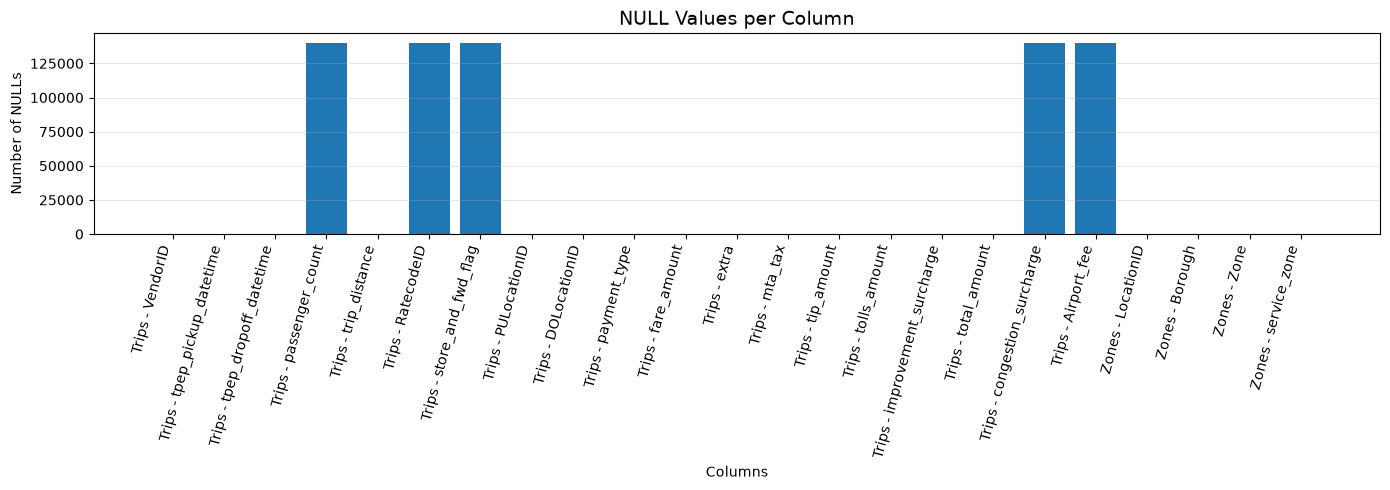

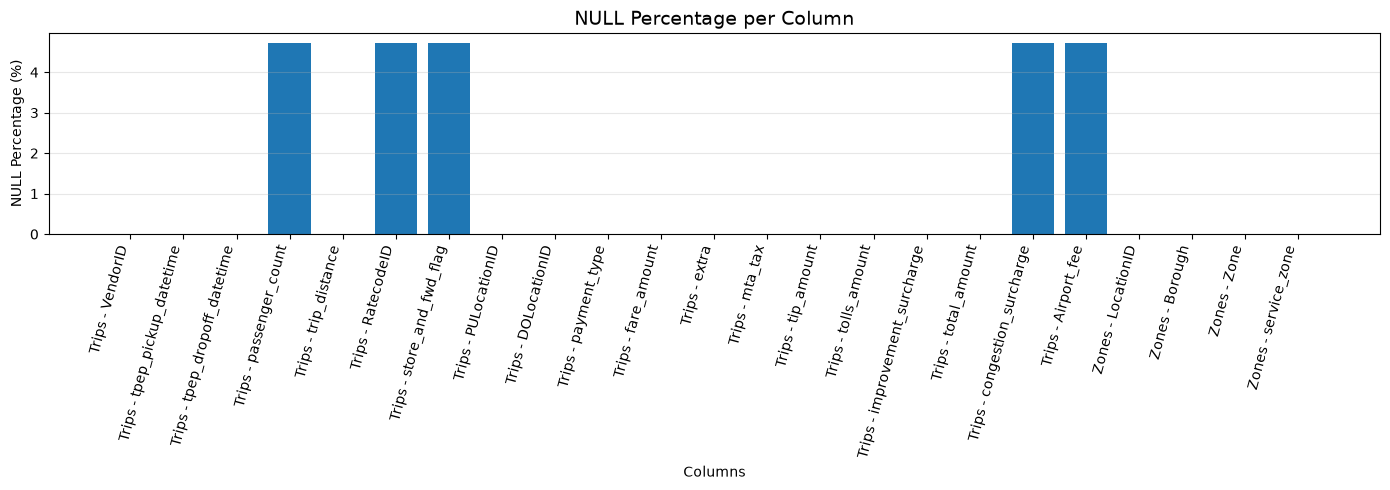

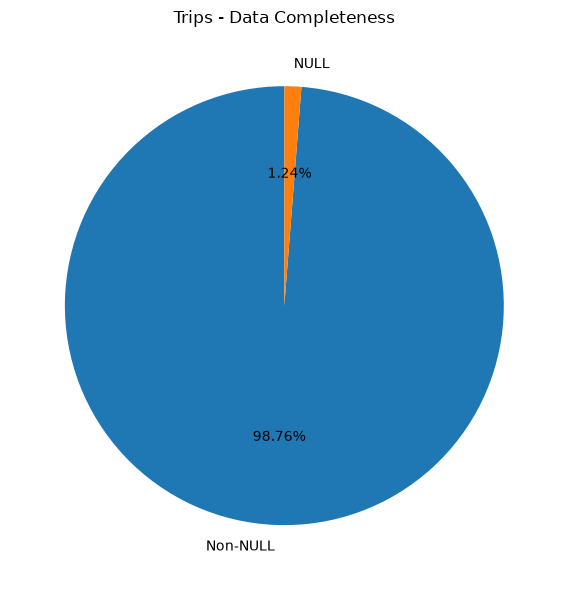

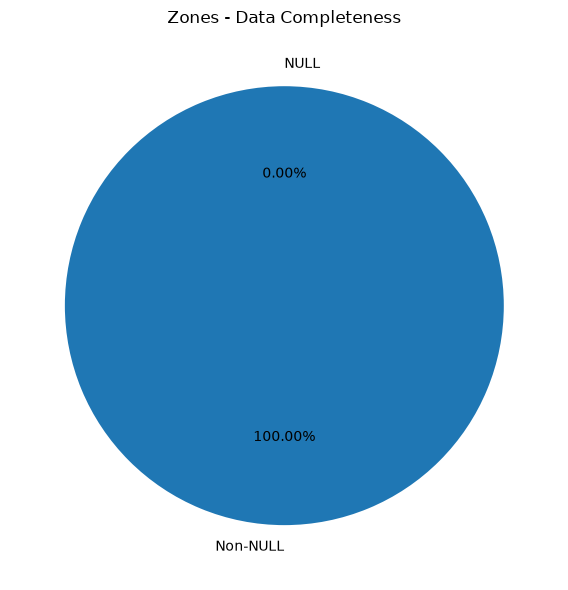

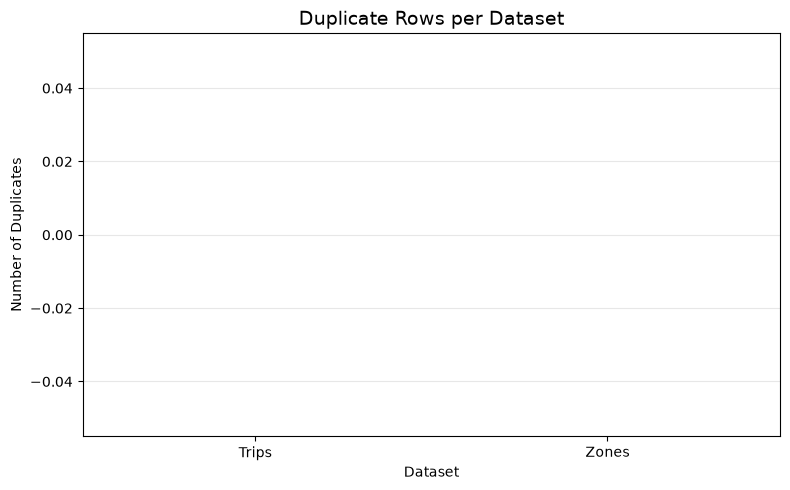

In [20]:

import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. PREPARE DATA FOR VISUALIZATION
# ==========================================

trips_pd = pd.DataFrame(
    null_trips_analysis,
    columns=["Column", "Null Count", "Null %", "Non-Null Count"]
)

zones_pd = pd.DataFrame(
    null_zones_analysis,
    columns=["Column", "Null Count", "Null %", "Non-Null Count"]
)

trips_pd["Dataset"] = "Trips"
zones_pd["Dataset"] = "Zones"

global_pd = pd.concat([trips_pd, zones_pd], ignore_index=True)

total_nulls = (
    sum(x[1] for x in null_trips_analysis) +
    sum(x[1] for x in null_zones_analysis)
)

total_duplicates = duplicate_trips_count + duplicate_zones_count

# ==========================================
# 2. DATASET OVERVIEW - KPIs
# ==========================================

kpi_report = pd.DataFrame({
    "Metric": [
        "Total Rows",
        "Total Columns",
        "Total NULL Values",
        "Total Duplicate Rows"
    ],
    "Trips": [
        total_trips_rows,
        len(trips.columns),
        sum(x[1] for x in null_trips_analysis),
        duplicate_trips_count
    ],
    "Zones": [
        total_zones_rows,
        len(zones.columns),
        sum(x[1] for x in null_zones_analysis),
        duplicate_zones_count
    ]
})

print("DATA QUALITY OVERVIEW")
display(kpi_report)

# ==========================================
# 3. NULL COUNT PER COLUMN
# ==========================================

plt.figure(figsize=(14, 5))

labels = global_pd["Dataset"] + " - " + global_pd["Column"]

plt.bar(labels, global_pd["Null Count"])

plt.title("NULL Values per Column", fontsize=14)
plt.xlabel("Columns")
plt.ylabel("Number of NULLs")
plt.xticks(rotation=75, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ==========================================
# 4. NULL PERCENTAGE PER COLUMN
# ==========================================

plt.figure(figsize=(14, 5))

plt.bar(labels, global_pd["Null %"])

plt.title("NULL Percentage per Column", fontsize=14)
plt.xlabel("Columns")
plt.ylabel("NULL Percentage (%)")
plt.xticks(rotation=75, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ==========================================
# 5. NULL vs NON-NULL DISTRIBUTION
# ==========================================

for dataset, total_rows, columns, nulls in [
    ("Trips", total_trips_rows, len(trips.columns),
     sum(x[1] for x in null_trips_analysis)),
    ("Zones", total_zones_rows, len(zones.columns),
     sum(x[1] for x in null_zones_analysis))
]:

    total_cells = total_rows * columns
    non_nulls = total_cells - nulls

    plt.figure(figsize=(6, 6))

    plt.pie(
        [non_nulls, nulls],
        labels=["Non-NULL", "NULL"],
        autopct="%1.2f%%",
        startangle=90
    )

    plt.title(f"{dataset} - Data Completeness")
    plt.tight_layout()
    plt.show()

# ==========================================
# 6. DUPLICATES COMPARISON
# ==========================================

plt.figure(figsize=(8, 5))

datasets = ["Trips", "Zones"]
duplicates = [
    duplicate_trips_count,
    duplicate_zones_count
]

plt.bar(datasets, duplicates)

plt.title("Duplicate Rows per Dataset", fontsize=14)
plt.xlabel("Dataset")
plt.ylabel("Number of Duplicates")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Observations — Nulls & Duplicates

- **700 810 nulls = 140 162 lignes × 5 colonnes** (`passenger_count`, `RatecodeID`, `store_and_fwd_flag`, `congestion_surcharge`, `Airport_fee`).
  Les nulls ne sont **pas aléatoires**: ils concernent **les mêmes 140 162 lignes (4.73 %)**, toutes avec `payment_type = 0` (Flex Fare) → courses dont les métadonnées ne sont pas transmises par le fournisseur.
- **Zones:** 0 null technique, mais 2 zones « inconnues » (264, 265) stockées en texte (`N/A`, `Unknown`).
- **Doublons exacts:** 0 (trips et zones).
- **Doublons logiques:** **31 109** lignes partagent la même course (vendor + horaires + zones). **31 101 / 31 109 groupes (99.97 %)** contiennent une ligne à montant négatif → ce sont des paires **course + correction** → traitées par le rejet des montants négatifs + déduplication en Silver.
- **Zones:** `LocationID` est bien une **clé unique** (265 / 265) → jointure trips ↔ zones fiable.

## 5. Data Dictionary

In [21]:
null_info = {("trips", c): (n, p) for c, n, p, _ in null_trips_analysis}
null_info.update({("zones", c): (n, p) for c, n, p, _ in null_zones_analysis})

# observations + action prevue en Silver (issues des sections 2, 3 et 4)
findings = {
    "VendorID": ("Valeurs 1, 2, 6", "Renommer vendor_id"),
    "tpep_pickup_datetime": ("18 lignes hors janvier 2024 (min 2002-12-31)", "Renommer pickup_datetime ; rejeter hors periode"),
    "tpep_dropoff_datetime": ("870 lignes avec dropoff <= pickup", "Renommer dropoff_datetime ; rejeter duree <= 0"),
    "passenger_count": ("Nulls (Flex Fare) + 31 465 lignes a 0 ; type long", "Cast int ; null -> 1 + flag d'imputation"),
    "trip_distance": ("60 371 lignes <= 0 ; max 312 722 miles", "Rejeter <= 0 et > 100 miles"),
    "RatecodeID": ("Nulls (Flex Fare) + 28 663 lignes a 99 ; type long", "Cast int ; null -> 99 (inconnu)"),
    "store_and_fwd_flag": ("Nulls (Flex Fare) ; valeurs Y/N", "null -> 'N'"),
    "PULocationID": ("Toutes dans 1-265", "Renommer pu_location_id ; FK vers zones"),
    "DOLocationID": ("Toutes dans 1-265", "Renommer do_location_id ; FK vers zones"),
    "payment_type": ("0 = Flex Fare (= lignes avec nulls) ; type long", "Cast int ; garder 0"),
    "fare_amount": ("37 448 lignes < 0 (min -899)", "Cast decimal(10,2) ; rejeter < 0"),
    "extra": ("Valeurs negatives (min -7.5)", "Cast decimal(10,2)"),
    "mta_tax": ("Valeurs negatives sur les corrections", "Cast decimal(10,2)"),
    "tip_amount": ("Pourboires especes absents", "Cast decimal(10,2)"),
    "tolls_amount": ("RAS", "Cast decimal(10,2)"),
    "improvement_surcharge": ("Valeurs negatives sur les corrections", "Cast decimal(10,2)"),
    "total_amount": ("35 504 lignes < 0 (min -900)", "Cast decimal(10,2) ; rejeter < 0"),
    "congestion_surcharge": ("Nulls (Flex Fare)", "Cast decimal(10,2) ; null -> 0"),
    "Airport_fee": ("Nulls (Flex Fare) ; nommage incoherent", "Renommer airport_fee ; null -> 0"),
    "LocationID": ("Cle unique 265/265", "Renommer location_id"),
    "Borough": ("'Unknown' / 'N/A' pour 264, 265", "Normaliser en 'Unknown'"),
    "Zone": ("'N/A' pour 264", "Normaliser en 'Unknown'"),
    "service_zone": ("'N/A' pour 264, 265", "Normaliser en 'Unknown'"),
}

dictionary_rows = []
for table, df in [("trips", trips), ("zones", zones)]:
    for col_name, col_type in df.dtypes:
        n, p = null_info[(table, col_name)]
        obs, action = findings[col_name]
        dictionary_rows.append((table, col_name, col_type, column_descriptions[col_name], n, float(p), obs, action))

data_dictionary = spark.createDataFrame(
    dictionary_rows,
    "table_name string, column_name string, data_type string, description string, "
    "null_count long, null_pct double, observations string, silver_action string",
)

data_dictionary.write.mode("overwrite").option("overwriteSchema", "true").saveAsTable(T_DATA_DICTIONARY)
print(f"Data Dictionary sauvegarde dans {T_DATA_DICTIONARY} ({data_dictionary.count()} colonnes documentees)")

Data Dictionary sauvegarde dans workspace.ops.data_dictionary (23 colonnes documentees)


In [22]:
spark.table(T_DATA_DICTIONARY).toPandas()

,table_name,column_name,data_type,description,null_count,null_pct,observations,silver_action
0,trips,VendorID,int,"Fournisseur TPEP: 1=Creative Mobile Technologies, 2=Curb Mobility, 6=Myle Technologies, 7=Helix",0,0.00,"Valeurs 1, 2, 6",Renommer vendor_id
1,trips,tpep_pickup_datetime,timestamp_ntz,Date/heure d'activation du taximètre (début de course),0,0.00,18 lignes hors janvier 2024 (min 2002-12-31),Renommer pickup_datetime ; rejeter hors periode
2,trips,tpep_dropoff_datetime,timestamp_ntz,Date/heure d'arrêt du taximètre (fin de course),0,0.00,870 lignes avec dropoff <= pickup,Renommer dropoff_datetime ; rejeter duree <= 0
3,trips,passenger_count,bigint,Nombre de passagers (saisi par le chauffeur),140162,4.73,Nulls (Flex Fare) + 31 465 lignes a 0 ; type long,Cast int ; null -> 1 + flag d'imputation
4,trips,trip_distance,double,Distance parcourue en miles (taximètre),0,0.00,60 371 lignes <= 0 ; max 312 722 miles,Rejeter <= 0 et > 100 miles
5,trips,RatecodeID,bigint,"Tarif final: 1=Standard, 2=JFK, 3=Newark, 4=Nassau/Westchester, 5=Négocié, 6=Group ride, 99=Inconnu",140162,4.73,Nulls (Flex Fare) + 28 663 lignes a 99 ; type long,Cast int ; null -> 99 (inconnu)
6,trips,store_and_fwd_flag,string,"Y = course stockée dans le véhicule avant envoi (pas de connexion), N = envoi direct",140162,4.73,Nulls (Flex Fare) ; valeurs Y/N,null -> 'N'
7,trips,PULocationID,int,Zone TLC de prise en charge (-> zones.LocationID),0,0.00,Toutes dans 1-265,Renommer pu_location_id ; FK vers zones
8,trips,DOLocationID,int,Zone TLC de dépose (-> zones.LocationID),0,0.00,Toutes dans 1-265,Renommer do_location_id ; FK vers zones
9,trips,payment_type,bigint,"Paiement: 0=Flex Fare, 1=Carte, 2=Espèces, 3=Gratuit, 4=Litige, 5=Inconnu, 6=Annulé",0,0.00,0 = Flex Fare (= lignes avec nulls) ; type long,Cast int ; garder 0


## 6. Conclusions

**Dataset:** 2 964 624 courses (19 colonnes) + 265 zones (4 colonnes).

**Top 5 des problèmes de qualité:**
1. **Montants négatifs** — 37 448 lignes (`fare_amount < 0`): remboursements / corrections.
2. **Distances invalides** — 60 371 lignes à 0 mile + valeurs aberrantes (jusqu'à 312 722 miles).
3. **Nulls structurés** — 140 162 lignes (4.73 %) sans métadonnées, toutes `payment_type = 0` (Flex Fare).
4. **Doublons logiques** — 31 109 lignes (paires course + correction).
5. **Hors période / durée invalide** — 18 pickups hors janvier 2024, 870 durées ≤ 0.

**Plan pour la Phase 4 (Silver):**
- **Type casting:** codes en `int`, montants en `decimal(10,2)`, renommage `snake_case`.
- **Nulls:** `passenger_count` → 1 (+ flag), `RatecodeID` → 99, `store_and_fwd_flag` → `N`, surcharges → 0.
- **Rejets** (table `rejected` avec motif): montants < 0, distance ≤ 0 ou > 100, durée ≤ 0 ou > 24 h, pickup hors période.
- **Déduplication** sur une clé de course.
- **Zones:** normaliser `N/A` / `Unknown`.

Le détail colonne par colonne est disponible dans la table **`workspace.ops.data_dictionary`**.